# 7. An end-to-end toxicity model on Tox21

**What you will learn:** how the pieces from notebooks 1-6 fit together into a
model you could actually hand to a colleague — including the two things that
decide whether its reported numbers mean anything: **missing labels** and the
**split**.

The data is Tox21, as distributed by MoleculeNet: 7,831 compounds screened
against 12 nuclear-receptor and stress-response assays. The two worked
examples here are

* **NR-AR** — androgen receptor agonism, and
* **SR-MMP** — disruption of the mitochondrial membrane potential.

Provenance, licence and references are in `data/README.md`. The file is
vendored in the repository, so this notebook runs offline.

Two facts about this data set shape everything below:

1. **Blank cells mean "not measured", not "inactive."** Not every compound was
   run in every assay. Filling blanks with zero invents thousands of negatives
   and inflates every metric. We carry a mask and score only measured entries.
2. **A few percent of compounds are active.** Accuracy is therefore useless —
   "never toxic" scores above 95% on NR-AR. We report ROC-AUC and PR-AUC, and
   always print the base rate next to them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

from mgnn.data import (
    TOX21_TASKS,
    WORKED_TASKS,
    class_balance,
    load_tox21_frame,
    load_tox21_graphs,
    task_summary,
)
from mgnn.models import MolecularGNN
from mgnn.splits import murcko_scaffold, scaffold_split
from mgnn.train import evaluate, predict, set_seed, train_model

plt.rcParams["figure.dpi"] = 110
torch.set_num_threads(4)
pd.set_option("display.width", 140)
set_seed(0)

## 7.1 Look at the data before you model it

This table takes two seconds to produce and prevents most of the ways a
toxicity model can be quietly wrong.

In [2]:
df = load_tox21_frame()
print(f"{len(df)} compounds, {len(TOX21_TASKS)} assays")
display(task_summary(df))

7831 compounds, 12 assays


,task,measured,missing,actives,inactives,pct_active,pct_missing
0,NR-AR,7265,566,309,6956,4.25,7.23
1,NR-AR-LBD,6758,1073,237,6521,3.51,13.70
2,NR-AhR,6549,1282,768,5781,11.73,16.37
3,NR-Aromatase,5821,2010,300,5521,5.15,25.67
4,NR-ER,6193,1638,793,5400,12.80,20.92
5,NR-ER-LBD,6955,876,350,6605,5.03,11.19
6,NR-PPAR-gamma,6450,1381,186,6264,2.88,17.64
7,SR-ARE,5832,1999,942,4890,16.15,25.53
8,SR-ATAD5,7072,759,264,6808,3.73,9.69
9,SR-HSE,6467,1364,372,6095,5.75,17.42


Read the `pct_missing` column: every assay is missing between roughly a sixth
and a third of the compounds. Read `pct_active`: the assays range from about
3% to about 16% active. NR-AR is among the scarcest, SR-MMP among the richest —
which is exactly why they make a useful pair of worked examples.

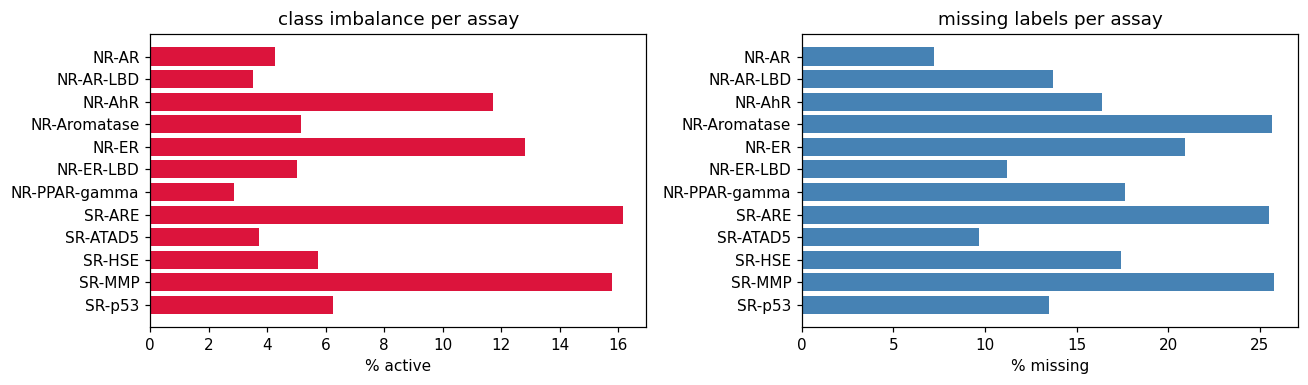

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
summary = task_summary(df)
axes[0].barh(summary["task"], summary["pct_active"], color="crimson")
axes[0].set_xlabel("% active"); axes[0].set_title("class imbalance per assay")
axes[0].invert_yaxis()
axes[1].barh(summary["task"], summary["pct_missing"], color="steelblue")
axes[1].set_xlabel("% missing"); axes[1].set_title("missing labels per assay")
axes[1].invert_yaxis()
fig.tight_layout()
plt.show()

## 7.2 Featurise

RDKit parses the SMILES and `mgnn.features` turns each molecule into
`x`, `edge_index`, `edge_attr`. A handful of compounds fail to parse — some
aluminium and tin species whose valences RDKit rejects — and they are dropped
and *counted*, not silently skipped.

In [4]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=True)
print(f"\n{len(ds)} molecules featurised, {ds.n_failed_parse} SMILES unparseable")
print("atoms per molecule: "
      f"median {np.median([g.num_nodes for g in ds.graphs]):.0f}, "
      f"max {max(g.num_nodes for g in ds.graphs)}")

Loaded 7823 featurised molecules from cache (tox21_NR-AR-SR-MMP_None.pkl)

7823 molecules featurised, 8 SMILES unparseable
atoms per molecule: median 16, max 132


## 7.3 The split is a modelling decision, not a formality

A **random** split puts close analogues of the same series on both sides of the
train/test line. The model then only has to recognise "this looks like
compound 412, which was toxic" — a task a fingerprint nearest-neighbour solves.
The reported number goes up and tells you nothing about the next series your
chemists will make.

A **scaffold** split (Bemis & Murcko, *J. Med. Chem.* 1996, 39 (15), 2887-2893,
DOI: [10.1021/jm9602928](https://doi.org/10.1021/jm9602928)) groups molecules
by their ring framework and keeps whole groups together, so test compounds have
frameworks the model has never seen.

We run **both**, on the same data with the same model, and compare. That
comparison is the most useful single number in this notebook.

In [5]:
train_idx, valid_idx, test_idx = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
d_train, d_valid, d_test = ds.subset(train_idx), ds.subset(valid_idx), ds.subset(test_idx)
print(f"scaffold split: {len(d_train)} train / {len(d_valid)} valid / {len(d_test)} test")

scaf_train = {murcko_scaffold(s) for s in d_train.smiles}
scaf_test = {murcko_scaffold(s) for s in d_test.smiles}
print(f"distinct scaffolds: {len(scaf_train)} train, {len(scaf_test)} test")
print("scaffolds shared between train and test:", len(scaf_train & scaf_test),
      " <- must be zero")

scaffold split: 6258 train / 782 valid / 783 test


distinct scaffolds: 760 train, 783 test
scaffolds shared between train and test: 0  <- must be zero


The class balance differs between the splits, and honestly so: the scaffold
split pushes unusual chemistry into the test set, which changes the active
rate there. Print it, because a ROC-AUC on 15 actives is a far noisier number
than one on 700.

In [6]:
rows = []
for name, d in [("train", d_train), ("valid", d_valid), ("test", d_test)]:
    for j, task in enumerate(WORKED_TASKS):
        bal = class_balance(d.y[:, j], d.y_mask[:, j])
        rows.append({"split": name, "task": task, "labelled": int(bal["n_labelled"]),
                     "actives": int(bal["actives"]), "% active": bal["pct_active"],
                     "implied pos_weight": bal["pos_weight"]})
display(pd.DataFrame(rows).set_index(["split", "task"]).style.format({
    "% active": "{:.2f}", "implied pos_weight": "{:.1f}"}))

## 7.4 The model

GIN layers (notebook 04: sum aggregation keeps neighbour counts), sum readout
(notebook 05: toxicity is closer to extensive than intensive), three layers
(notebook 06: molecules are small and deeper smooths), two output units — one
per assay, trained jointly.

**Multi-task** training is the right default here: the assays share chemistry,
and a compound measured in SR-MMP but not NR-AR still teaches the shared layers
something. The mask makes that safe.

The `pos_weight` values are taken from the training-set imbalance, rounded —
they tell the optimiser that the few actives matter as much as the many
inactives.

In [7]:
set_seed(0)
model = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind="gin",
                     pooling="sum", dropout=0.1)
print(model.layer_kind, "/", model.pooling_kind, "/", model.n_layers, "layers")
print("trainable parameters:", model.n_parameters())

pos_weight = torch.tensor([5.0, 3.0])
history = train_model(model, d_train.graphs, d_valid.graphs, WORKED_TASKS,
                      epochs=40, batch_size=64, lr=1e-3, weight_decay=1e-5,
                      pos_weight=pos_weight, seed=0, verbose=True,
                      early_stopping_patience=12)
print(f"\nbest validation ROC-AUC {history.best_valid_roc_auc:.3f} "
      f"at epoch {history.best_epoch} (those weights are restored)")

gin / sum / 3 layers
trainable parameters: 32325


epoch   1 | train loss 0.7485 | valid ROC-AUC 0.695 | valid PR-AUC 0.320


epoch   2 | train loss 0.6263 | valid ROC-AUC 0.693 | valid PR-AUC 0.297


epoch   3 | train loss 0.6098 | valid ROC-AUC 0.706 | valid PR-AUC 0.372


epoch   4 | train loss 0.5895 | valid ROC-AUC 0.692 | valid PR-AUC 0.306


epoch   5 | train loss 0.5723 | valid ROC-AUC 0.707 | valid PR-AUC 0.369


... (25 outputs left out)

epoch  31 | train loss 0.3856 | valid ROC-AUC 0.758 | valid PR-AUC 0.531


epoch  32 | train loss 0.3833 | valid ROC-AUC 0.761 | valid PR-AUC 0.531


epoch  33 | train loss 0.3927 | valid ROC-AUC 0.751 | valid PR-AUC 0.549


epoch  34 | train loss 0.3855 | valid ROC-AUC 0.751 | valid PR-AUC 0.540
early stop at epoch 34 (no improvement for 12 epochs)

best validation ROC-AUC 0.781 at epoch 22 (those weights are restored)


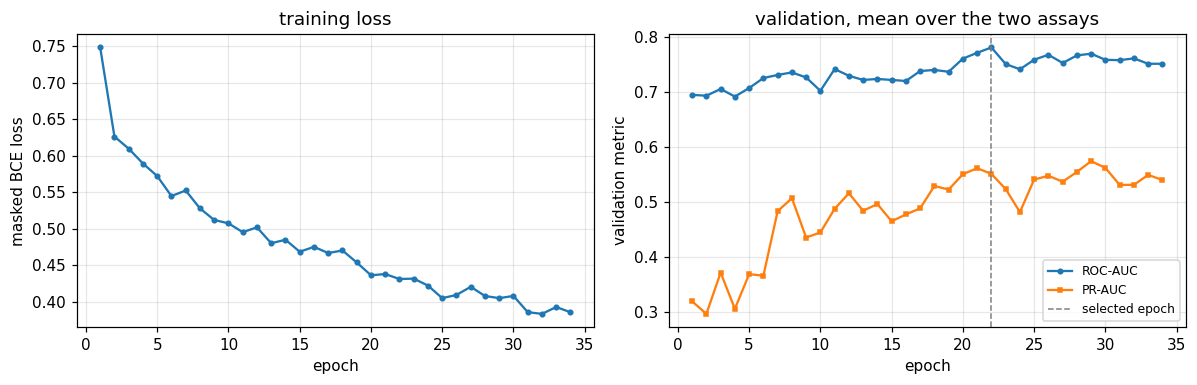

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(range(1, len(history.train_loss) + 1), history.train_loss, marker="o", ms=3)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("masked BCE loss"); axes[0].set_title("training loss")
axes[1].plot(range(1, len(history.valid_roc_auc) + 1), history.valid_roc_auc,
             marker="o", ms=3, label="ROC-AUC")
axes[1].plot(range(1, len(history.valid_pr_auc) + 1), history.valid_pr_auc,
             marker="s", ms=3, label="PR-AUC")
axes[1].axvline(history.best_epoch, color="grey", ls="--", lw=1, label="selected epoch")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation metric"); axes[1].legend(fontsize=8)
axes[1].set_title("validation, mean over the two assays")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 7.5 Test-set results on the scaffold split

The numbers below are what this model, this seed and this split produced when
the notebook was run. No cherry-picking across seeds, and the base rate is
printed beside each metric so a PR-AUC can be read against the floor it has to
beat (a random ranker scores PR-AUC ≈ the base rate).

In [9]:
test_metrics = evaluate(model, d_test.graphs, WORKED_TASKS)
rows = []
for task, m in test_metrics["per_task"].items():
    rows.append({"task": task, "labelled in test": m["n"], "actives": m["n_active"],
                 "base rate": m.get("base_rate", float("nan")),
                 "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"]})
results = pd.DataFrame(rows).set_index("task")
display(results.style.format({"base rate": "{:.3f}", "ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}"}))
print(f"mean test ROC-AUC over the two assays: {test_metrics['mean_roc_auc']:.3f}")
print(f"mean test PR-AUC  over the two assays: {test_metrics['mean_pr_auc']:.3f}")

,labelled in test,actives,base rate,ROC-AUC,PR-AUC
task,,,,,
NR-AR,704,15,0.021,0.575,0.030
SR-MMP,473,92,0.195,0.816,0.502


mean test ROC-AUC over the two assays: 0.696
mean test PR-AUC  over the two assays: 0.266


### Reading these numbers honestly

* **NR-AR has very few actives in a scaffold-split test set.** Its ROC-AUC is
  therefore a high-variance estimate: a handful of compounds moving in the
  ranking swings it by several points. Quote it with the active count attached,
  or not at all.
* **PR-AUC is the harder and more informative metric** under this much
  imbalance. Compare it with the base rate column, not with 0.5.
* A single seed on a single split is a data point, not a result. The honest
  version of this table in a paper has error bars over several seeds and
  several scaffold splits; `train_model` takes a `seed` argument so you can
  produce them.

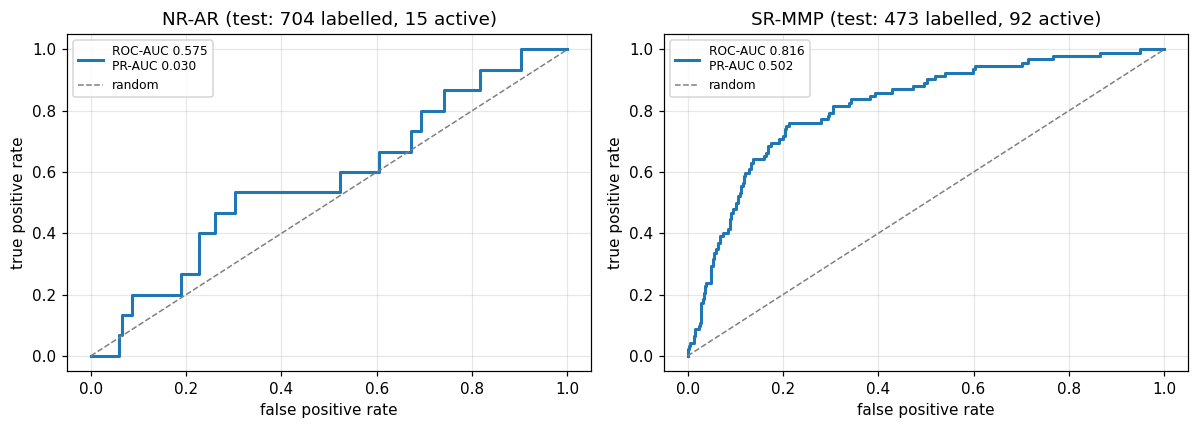

In [10]:
logits, y, mask = predict(model, d_test.graphs)
probs = torch.sigmoid(logits).numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (j, task) in zip(axes, enumerate(WORKED_TASKS)):
    m = mask.numpy()[:, j]
    yt, pt = y.numpy()[m, j], probs[m, j]
    if len(np.unique(yt)) > 1:
        fpr, tpr, _ = roc_curve(yt, pt)
        ax.plot(fpr, tpr, lw=2,
                label=f"ROC-AUC {roc_auc_score(yt, pt):.3f}\nPR-AUC {average_precision_score(yt, pt):.3f}")
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="random")
    ax.set_title(f"{task} (test: {int(m.sum())} labelled, {int((yt == 1).sum())} active)")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 7.6 How much does a random split flatter the model?

Same architecture, same hyper-parameters, same seed, same number of epochs —
only the split changes. Everything else held constant, the gap between the two
test numbers is the size of the optimism a random split buys you.

In [11]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(ds))
n_tr, n_va = int(0.8 * len(ds)), int(0.1 * len(ds))
r_train = ds.subset(sorted(perm[:n_tr].tolist()))
r_valid = ds.subset(sorted(perm[n_tr:n_tr + n_va].tolist()))
r_test = ds.subset(sorted(perm[n_tr + n_va:].tolist()))

shared = {murcko_scaffold(s) for s in r_train.smiles} & {murcko_scaffold(s) for s in r_test.smiles}
print(f"random split: {len(r_train)} / {len(r_valid)} / {len(r_test)}")
print(f"scaffolds shared between train and test: {len(shared)}  <- the leak")

set_seed(0)
model_rand = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind="gin",
                          pooling="sum", dropout=0.1)
hist_rand = train_model(model_rand, r_train.graphs, r_valid.graphs, WORKED_TASKS,
                        epochs=40, batch_size=64, lr=1e-3, weight_decay=1e-5,
                        pos_weight=pos_weight, seed=0, verbose=False,
                        early_stopping_patience=12)
rand_metrics = evaluate(model_rand, r_test.graphs, WORKED_TASKS)

comparison = pd.DataFrame({
    "scaffold split": {
        "NR-AR ROC-AUC": test_metrics["per_task"]["NR-AR"]["roc_auc"],
        "SR-MMP ROC-AUC": test_metrics["per_task"]["SR-MMP"]["roc_auc"],
        "mean ROC-AUC": test_metrics["mean_roc_auc"],
        "mean PR-AUC": test_metrics["mean_pr_auc"],
    },
    "random split": {
        "NR-AR ROC-AUC": rand_metrics["per_task"]["NR-AR"]["roc_auc"],
        "SR-MMP ROC-AUC": rand_metrics["per_task"]["SR-MMP"]["roc_auc"],
        "mean ROC-AUC": rand_metrics["mean_roc_auc"],
        "mean PR-AUC": rand_metrics["mean_pr_auc"],
    },
})
comparison["difference"] = comparison["random split"] - comparison["scaffold split"]
display(comparison.style.format("{:.3f}"))

random split: 6258 / 782 / 783
scaffolds shared between train and test: 172  <- the leak


,scaffold split,random split,difference
NR-AR ROC-AUC,0.575,0.805,0.230
SR-MMP ROC-AUC,0.816,0.886,0.070
mean ROC-AUC,0.696,0.846,0.150
mean PR-AUC,0.266,0.587,0.321


Whatever the exact size of the gap in this run, the direction is the point and
it is structural, not statistical: the random split's test set contains
analogues of training compounds, so part of what the model is being credited
with is recall rather than generalisation.

**This is why MoleculeNet reports Tox21 under a scaffold split, and why a
paper quoting random-split Tox21 numbers against scaffold-split baselines is
not comparing like with like.**

## 7.7 A baseline, so the GNN has to earn its keep

Any molecular model should be compared against a Morgan-fingerprint + random
forest baseline. It takes thirty seconds to fit and it is embarrassingly hard
to beat on small data sets. Reporting a GNN without one is how papers end up
claiming improvements that a 2010 pipeline already had.

In [12]:
from rdkit import Chem  # noqa: E402
from rdkit.Chem import rdFingerprintGenerator  # noqa: E402
from sklearn.ensemble import RandomForestClassifier  # noqa: E402

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def fingerprints(smiles_list):
    X = np.zeros((len(smiles_list), 2048), dtype=np.int8)
    for i, smi in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            X[i] = np.array(gen.GetFingerprintAsNumPy(mol), dtype=np.int8)
    return X

X_train, X_test = fingerprints(d_train.smiles), fingerprints(d_test.smiles)

baseline_rows = []
for j, task in enumerate(WORKED_TASKS):
    m_tr, m_te = d_train.y_mask[:, j], d_test.y_mask[:, j]
    y_tr, y_te = d_train.y[m_tr, j], d_test.y[m_te, j]
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                n_jobs=4, random_state=0)
    rf.fit(X_train[m_tr], y_tr)
    p = rf.predict_proba(X_test[m_te])[:, 1]
    baseline_rows.append({
        "task": task,
        "RF ROC-AUC": roc_auc_score(y_te, p) if len(np.unique(y_te)) > 1 else float("nan"),
        "RF PR-AUC": average_precision_score(y_te, p) if len(np.unique(y_te)) > 1 else float("nan"),
        "GIN ROC-AUC": test_metrics["per_task"][task]["roc_auc"],
        "GIN PR-AUC": test_metrics["per_task"][task]["pr_auc"],
    })
display(pd.DataFrame(baseline_rows).set_index("task").style.format("{:.3f}"))

,RF ROC-AUC,RF PR-AUC,GIN ROC-AUC,GIN PR-AUC
task,,,,
NR-AR,0.497,0.026,0.575,0.030
SR-MMP,0.755,0.456,0.816,0.502


Whichever way this table falls in your run, the lesson is the same one every
practitioner eventually learns: on a few thousand molecules, a well-tuned
fingerprint baseline is competitive with a graph network, and the GNN's real
advantages (learned features that transfer, end-to-end differentiability,
per-atom interpretability) show up at larger scale or when you need the atom
attributions that notebook 08 produces.

## 7.8 Saving the model

`*.pt` files are git-ignored, so this writes outside the repository's tracked
content. Keep weights out of the repository and publish a script that
reproduces them instead.

In [13]:
import tempfile, os  # noqa: E402

path = os.path.join(tempfile.gettempdir(), "tox21_gin.pt")
torch.save({"state_dict": model.state_dict(),
            "tasks": WORKED_TASKS,
            "config": {"hidden_dim": 64, "n_layers": 3,
                       "layer_kind": "gin", "pooling": "sum"},
            "test_metrics": test_metrics}, path)
print("saved to", path, f"({os.path.getsize(path) / 1024:.0f} kB)")

saved to /tmp/tox21_gin.pt (135 kB)


## What to take away

* Print the label and imbalance table before you train anything.
* Mask missing labels; never impute them as inactive.
* Report ROC-AUC **and** PR-AUC, with base rates and active counts beside them.
* Use a scaffold split, and if you must quote a random-split number, quote both.
* Always run the fingerprint baseline.

**Next:** notebook 08 asks the model *why* — which atoms drove a prediction,
via attention weights and gradient attribution drawn on the structure.